# Splat Field Spatial Holdout

This notebook evaluates a rasterized spatial holdout task derived from
`splat_field_modular_clean.ipynb`.

The supervision units here are rasterized active grid measurements rather than
the original cells. We assign active measurements to a checkerboard pattern:

- observed checkerboard tiles are used for training and validation
- held-out checkerboard tiles are used as the imputation target

The goal is to test whether the learned field can reconstruct unobserved
measurements from spatial structure.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import random
import torch
import torch.nn as nn

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import (
    AmplitudeSplatField,
    DataConfig,
    SplatConfig,
    TrainingConfig,
    build_spatial_targets,
    capture_initial_splat_state,
    composition_cosine_loss,
    compute_splat_weights,
    create_amplitude_splat_optimizer,
    evaluate_cell_readout,
    evaluate_count_model,
    farthest_point_sample_indices,
    log_total_count_loss,
    mae_count_loss,
    predict_cell_log_rates,
    sample_tissue_support,
)
from spatsplat.baselines import CountMLP, FourierFeatureMLP, KNNCountRegressor, MeanProfileBaseline
from spatsplat.models import SplatBiologyDecoder
from paper.data_loaders.xenium_mouse_brain import load_tiny_xenium_dataset


In [2]:
data_cfg = DataConfig(bin_size=64, mask_grid_size=128, qv_threshold=20, cell_mask_min_radius=1.0)
splat_cfg = SplatConfig(
    num_splats=128,
    latent_dim=32,
    hidden_dim=128,
    init_log_scale=-3.5,
    kernel_sharpness=0.2,
)
init_log_amplitude = 8.0
train_cfg = TrainingConfig(
    baseline_epochs=100,
    splat_epochs=200,
    baseline_batch_size=2048,
    cell_batch_size=2048,
    off_tissue_batch_size=2048,
    cell_loss_weight=1.0,
    off_tissue_weight=1.0e-5,
    center_support_weight=0.001,
    splat_means_lr=5e-3,
    splat_log_scales_lr=1e-3,
    splat_rotation_lr=1e-3,
    splat_opacity_lr=1e-3,
    splat_latents_lr=1e-3,
    splat_log_theta_lr=1e-3,
    splat_decoder_lr=1e-3,
    splat_total_count_head_lr=1e-3,
)

notebook_seed = 1107
ae_seed = notebook_seed + 1
spatial_split_seed = notebook_seed + 2
seed_init_seed = notebook_seed + 3
baseline_mean_seed = notebook_seed + 4
baseline_mlp_mae_seed = notebook_seed + 5
baseline_fourier_mae_seed = notebook_seed + 6
baseline_budget_knn_seed = notebook_seed + 7
random_model_seed = notebook_seed + 8
random_train_seed = notebook_seed + 9
ae_train_seed = notebook_seed + 10
layout_seed = notebook_seed + 11


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(notebook_seed)
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

FIGURE_EXPORT_DIR = PROJECT_ROOT / "figures" / "splat_field_modular_spatial_holdout"
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
figure_export_dir = FIGURE_EXPORT_DIR

def _slugify_figure_name(name: str) -> str:
    keep = []
    for ch in name.lower():
        if ch.isalnum():
            keep.append(ch)
        elif ch in {" ", "-", "_", "|"}:
            keep.append("_")
    slug = "".join(keep).strip("_")
    while "__" in slug:
        slug = slug.replace("__", "_")
    return slug or "untitled_figure"

def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths


In [3]:
loaded = load_tiny_xenium_dataset()
dataset = build_spatial_targets(loaded, data_cfg)

device = loaded.device
trans_df = loaded.trans_df
adata = loaded.adata
gene_list = loaded.gene_list
gene_to_id = loaded.gene_to_id
num_genes = loaded.num_genes

cell_features = dataset.cell_features
cell_spans = dataset.cell_spans
cell_targets = dataset.cell_targets
bin_features = dataset.bin_features
bin_targets = dataset.bin_targets
tissue_mask_tensor = dataset.tissue_mask_tensor
off_tissue_points = dataset.off_tissue_points

measurement_features = bin_features
measurement_targets = bin_targets
measurement_spans = torch.full_like(
    measurement_features,
    fill_value=1.0 / data_cfg.bin_size,
)

raw_cell_points_np = cell_features.detach().cpu().numpy()
measurement_points_np = measurement_features.detach().cpu().numpy()
measurement_totals_np = measurement_targets.sum(dim=1).detach().cpu().numpy()
mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy()

print(f"Device: {device}")
print(f"Filtered transcripts: {len(trans_df):,}")
print(f"Genes: {num_genes:,}")
print(f"Original cells: {len(cell_features):,}")
print(f"Active rasterized measurements: {len(measurement_features):,}")
print(f"Bin size: {data_cfg.bin_size}")
print(f"Mask grid size: {data_cfg.mask_grid_size}")


Device: cuda
Filtered transcripts: 9,447,344
Genes: 248
Original cells: 36,553
Active rasterized measurements: 2,923
Bin size: 64
Mask grid size: 128


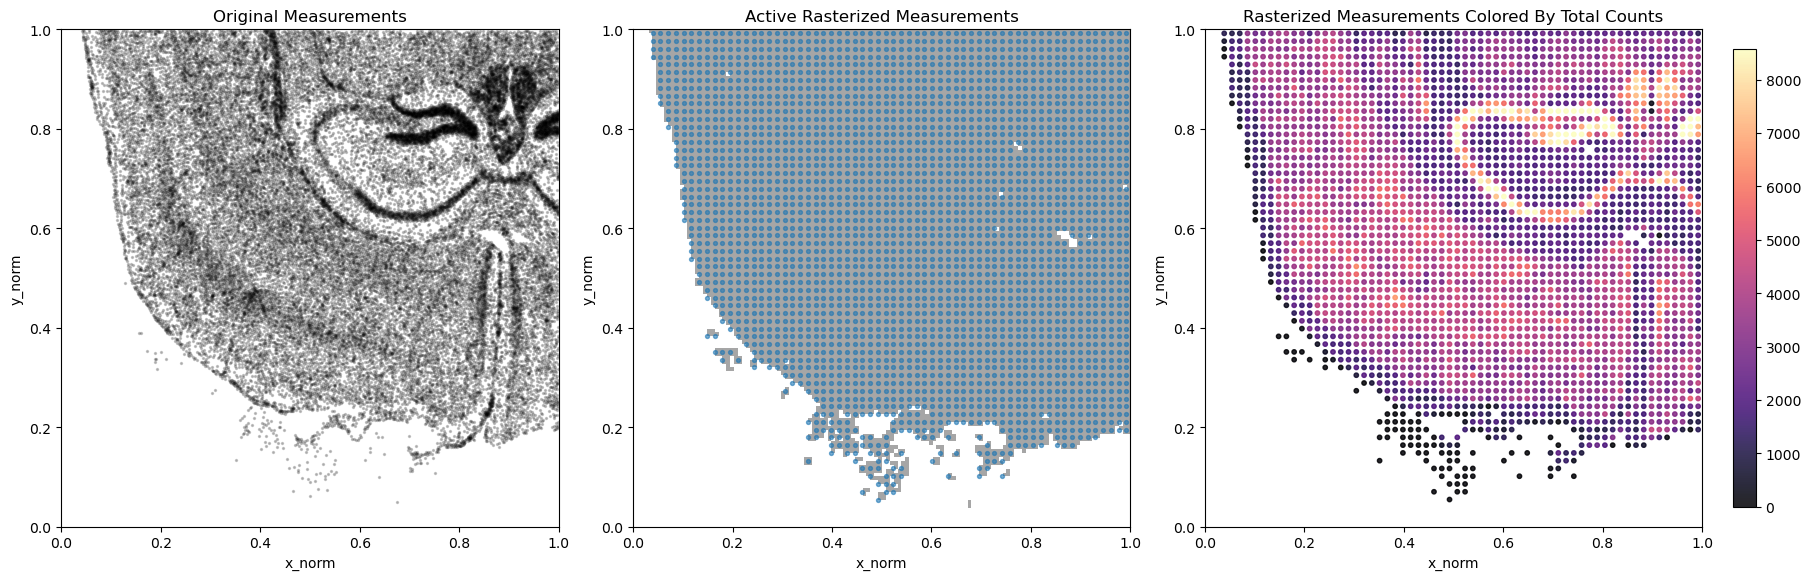

In [4]:
sample_n = min(50000, len(raw_cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(raw_cell_points_np), size=sample_n, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

axes[0].scatter(raw_cell_points_np[sample_idx, 0], raw_cell_points_np[sample_idx, 1], s=2, alpha=0.2, color="black")
axes[0].set_title("Original Measurements")

axes[1].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.35)
axes[1].scatter(measurement_points_np[:, 0], measurement_points_np[:, 1], s=8, alpha=0.6, color="tab:blue")
axes[1].set_title("Active Rasterized Measurements")

vmax = np.quantile(measurement_totals_np, 0.99) if len(measurement_totals_np) else 1.0
sc = axes[2].scatter(
    measurement_points_np[:, 0],
    measurement_points_np[:, 1],
    c=measurement_totals_np,
    s=10,
    cmap="magma",
    alpha=0.85,
    vmin=0.0,
    vmax=vmax,
)
axes[2].set_title("Rasterized Measurements Colored By Total Counts")
fig.colorbar(sc, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix="dataset_overview")
plt.show()

In [5]:
def build_checkerboard_holdout(features: torch.Tensor, *, grid_size: int, seed: int, val_fraction: float = 0.1):
    coords = features.detach().cpu().numpy()
    gx = np.clip((coords[:, 0] * grid_size).astype(np.int32), 0, grid_size - 1)
    gy = np.clip((coords[:, 1] * grid_size).astype(np.int32), 0, grid_size - 1)
    parity = (gx + gy) % 2

    observed_mask = parity == 0
    heldout_mask = parity == 1

    observed_idx = np.flatnonzero(observed_mask)
    heldout_idx = np.flatnonzero(heldout_mask)

    rng = np.random.default_rng(seed)
    observed_perm = rng.permutation(observed_idx)
    val_count = max(1, int(round(val_fraction * len(observed_perm))))
    val_idx_np = np.sort(observed_perm[:val_count])
    train_idx_np = np.sort(observed_perm[val_count:])
    test_idx_np = np.sort(heldout_idx)

    summary = {
        "observed_measurements": int(len(observed_idx)),
        "heldout_measurements": int(len(heldout_idx)),
        "train_measurements": int(len(train_idx_np)),
        "val_measurements": int(len(val_idx_np)),
        "test_measurements": int(len(test_idx_np)),
        "train_fraction_of_all": float(len(train_idx_np) / len(features)),
        "heldout_fraction_of_all": float(len(test_idx_np) / len(features)),
    }

    return (
        torch.from_numpy(train_idx_np).to(features.device, dtype=torch.long),
        torch.from_numpy(val_idx_np).to(features.device, dtype=torch.long),
        torch.from_numpy(test_idx_np).to(features.device, dtype=torch.long),
        gx,
        gy,
        parity,
        summary,
    )

measurement_train_idx, measurement_val_idx, measurement_test_idx, measurement_gx, measurement_gy, measurement_parity, split_summary = build_checkerboard_holdout(
    measurement_features,
    grid_size=data_cfg.bin_size,
    seed=spatial_split_seed,
    val_fraction=0.1,
)

print("Checkerboard spatial split summary")
print(format_for_display(split_summary))

train_mask_np = np.zeros(len(measurement_features), dtype=bool)
val_mask_np = np.zeros(len(measurement_features), dtype=bool)
test_mask_np = np.zeros(len(measurement_features), dtype=bool)
train_mask_np[measurement_train_idx.detach().cpu().numpy()] = True
val_mask_np[measurement_val_idx.detach().cpu().numpy()] = True
test_mask_np[measurement_test_idx.detach().cpu().numpy()] = True

Checkerboard spatial split summary
{'observed_measurements': 1462, 'heldout_measurements': 1461, 'train_measurements': 1316, 'val_measurements': 146, 'test_measurements': 1461, 'train_fraction_of_all': 0.4502, 'heldout_fraction_of_all': 0.4998}


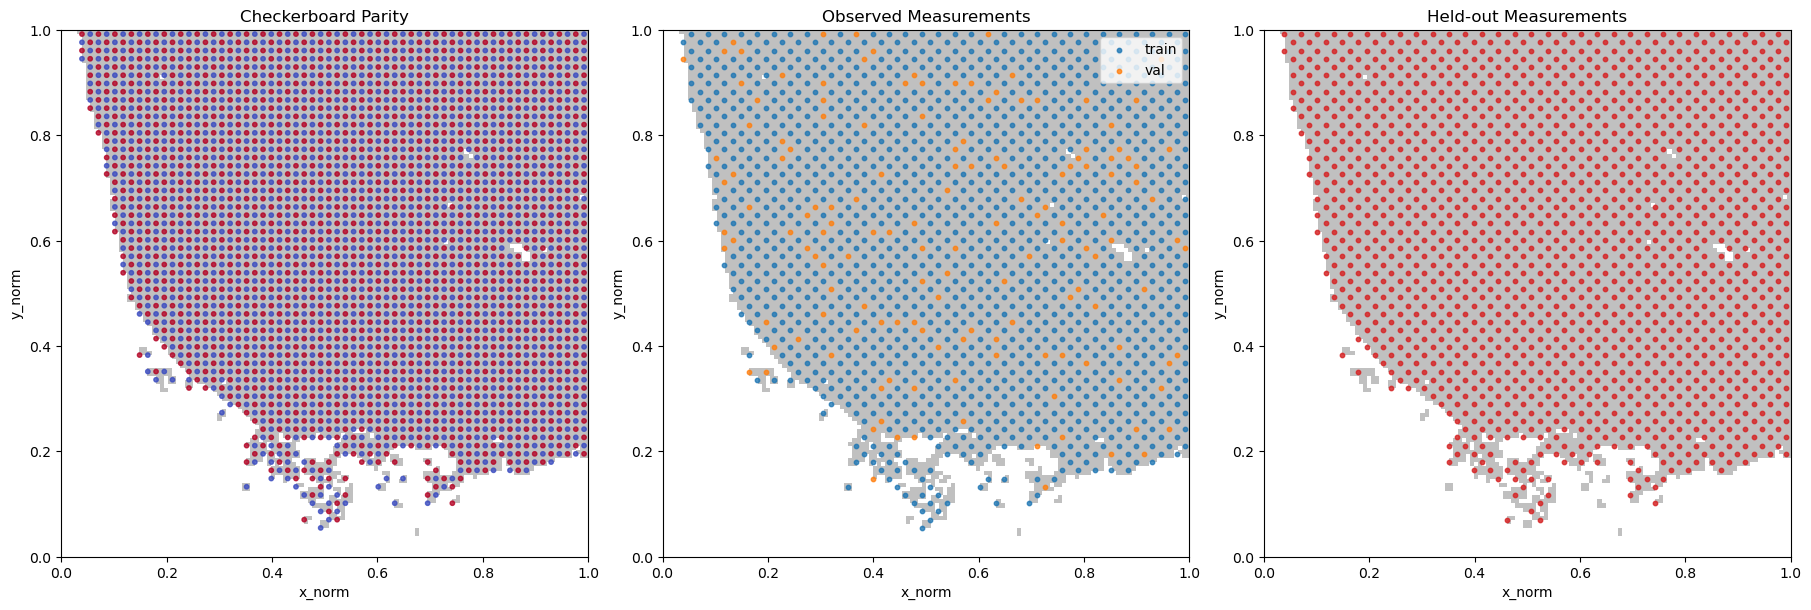

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

axes[0].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
axes[0].scatter(measurement_points_np[:, 0], measurement_points_np[:, 1], c=measurement_parity, s=10, cmap="coolwarm", alpha=0.8)
axes[0].set_title("Checkerboard Parity")

axes[1].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
axes[1].scatter(measurement_points_np[train_mask_np, 0], measurement_points_np[train_mask_np, 1], s=10, alpha=0.8, color="tab:blue", label="train")
axes[1].scatter(measurement_points_np[val_mask_np, 0], measurement_points_np[val_mask_np, 1], s=10, alpha=0.8, color="tab:orange", label="val")
axes[1].set_title("Observed Measurements")
axes[1].legend(loc="upper right")

axes[2].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
axes[2].scatter(measurement_points_np[test_mask_np, 0], measurement_points_np[test_mask_np, 1], s=10, alpha=0.85, color="tab:red")
axes[2].set_title("Held-out Measurements")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix="checkerboard_split")
plt.show()

AE epoch 0 | train_loss=5.499 | val={'loss': 5.483, 'mae': 0.004561, 'cosine': 0.4559, 'n': 146}
AE epoch 24 | train_loss=4.975 | val={'loss': 4.983, 'mae': 0.003238, 'cosine': 0.7182, 'n': 146}
AE epoch 49 | train_loss=4.8 | val={'loss': 4.812, 'mae': 0.002609, 'cosine': 0.823, 'n': 146}
AE epoch 74 | train_loss=4.707 | val={'loss': 4.748, 'mae': 0.002319, 'cosine': 0.8604, 'n': 146}
AE epoch 99 | train_loss=4.654 | val={'loss': 4.713, 'mae': 0.002117, 'cosine': 0.8826, 'n': 146}
AE epoch 124 | train_loss=4.639 | val={'loss': 4.706, 'mae': 0.002044, 'cosine': 0.8909, 'n': 146}
AE epoch 149 | train_loss=4.614 | val={'loss': 4.699, 'mae': 0.001987, 'cosine': 0.896, 'n': 146}
AE epoch 174 | train_loss=4.589 | val={'loss': 4.699, 'mae': 0.001956, 'cosine': 0.8971, 'n': 146}
AE epoch 199 | train_loss=4.568 | val={'loss': 4.697, 'mae': 0.001928, 'cosine': 0.8999, 'n': 146}
AE epoch 224 | train_loss=4.574 | val={'loss': 4.699, 'mae': 0.001897, 'cosine': 0.9021, 'n': 146}
AE epoch 249 | train

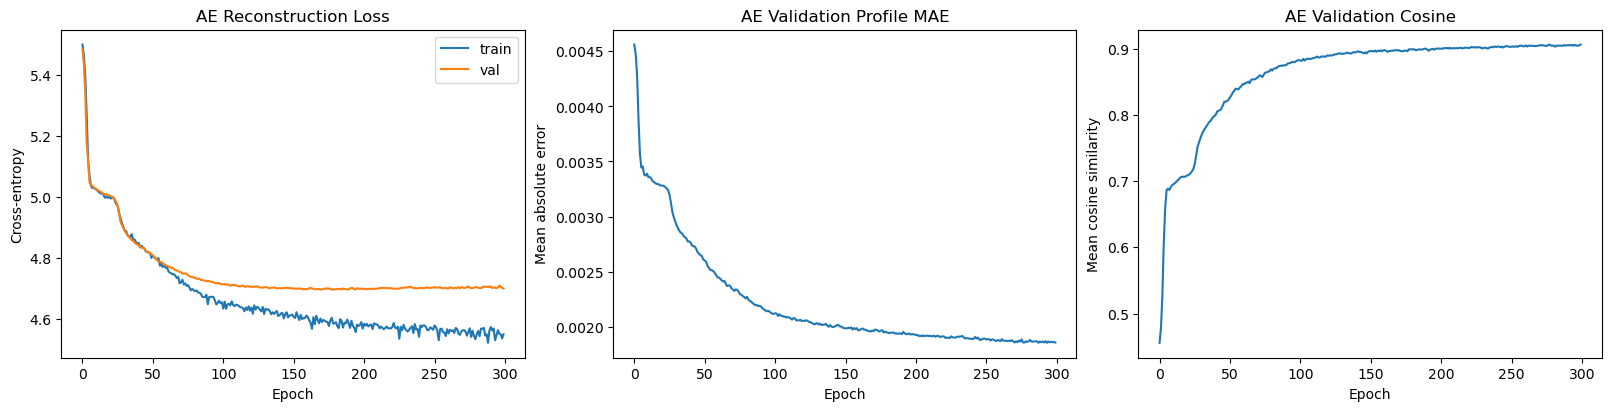

In [7]:
measurement_total_counts = measurement_targets.sum(dim=1, keepdim=True).clamp_min(1.0)
measurement_profiles = measurement_targets.float() / measurement_total_counts

ae_epochs = 300
ae_batch_size = 256
ae_lr = 1e-3

class GeneProfileEncoder(nn.Module):
    def __init__(self, num_genes: int, hidden_dim: int, latent_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(num_genes, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, latent_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

class GeneProfileAutoencoder(nn.Module):
    def __init__(self, num_genes: int, hidden_dim: int, latent_dim: int):
        super().__init__()
        self.encoder = GeneProfileEncoder(num_genes=num_genes, hidden_dim=hidden_dim, latent_dim=latent_dim)
        self.decoder = SplatBiologyDecoder(latent_dim=latent_dim, hidden_dim=hidden_dim, num_genes=num_genes)

    def forward(self, profiles: torch.Tensor):
        z = self.encoder(profiles)
        gene_logits, _ = self.decoder(z)
        recon_profiles = torch.softmax(gene_logits, dim=1)
        return z, gene_logits, recon_profiles

def profile_reconstruction_loss(target_profiles: torch.Tensor, pred_profiles: torch.Tensor) -> torch.Tensor:
    return -(target_profiles * pred_profiles.clamp_min(1e-8).log()).sum(dim=1).mean()

def evaluate_profile_autoencoder(model, profiles: torch.Tensor, idx: torch.Tensor, batch_size: int = 512):
    was_training = model.training
    model.eval()
    losses = []
    maes = []
    cosines = []
    with torch.no_grad():
        for start in range(0, len(idx), batch_size):
            batch_idx = idx[start:start + batch_size]
            batch_profiles = profiles[batch_idx]
            _, _, recon_profiles = model(batch_profiles)
            losses.append(profile_reconstruction_loss(batch_profiles, recon_profiles).item())
            maes.append((recon_profiles - batch_profiles).abs().mean(dim=1))
            recon_norm = recon_profiles / recon_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
            target_norm = batch_profiles / batch_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
            cosines.append((recon_norm * target_norm).sum(dim=1))
    if was_training:
        model.train()
    mae_tensor = torch.cat(maes) if maes else torch.empty(0)
    cosine_tensor = torch.cat(cosines) if cosines else torch.empty(0)
    return {
        "loss": float(np.mean(losses)) if losses else float("nan"),
        "mae": float(mae_tensor.mean().item()) if len(mae_tensor) else float("nan"),
        "cosine": float(cosine_tensor.mean().item()) if len(cosine_tensor) else float("nan"),
        "n": int(len(idx)),
    }

set_seed(ae_seed)
profile_autoencoder = GeneProfileAutoencoder(
    num_genes=num_genes,
    hidden_dim=splat_cfg.hidden_dim,
    latent_dim=splat_cfg.latent_dim,
).to(device)
profile_autoencoder_opt = torch.optim.Adam(profile_autoencoder.parameters(), lr=ae_lr)

ae_history = {"train_loss": [], "val_loss": [], "val_mae": [], "val_cosine": []}
for epoch in range(ae_epochs):
    profile_autoencoder.train()
    perm = measurement_train_idx[torch.randperm(len(measurement_train_idx), device=device)]
    running_loss = 0.0
    num_batches = 0

    for start in range(0, len(perm), ae_batch_size):
        batch_idx = perm[start:start + ae_batch_size]
        batch_profiles = measurement_profiles[batch_idx]
        _, _, recon_profiles = profile_autoencoder(batch_profiles)
        loss = profile_reconstruction_loss(batch_profiles, recon_profiles)

        profile_autoencoder_opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(profile_autoencoder.parameters(), max_norm=5.0)
        profile_autoencoder_opt.step()

        running_loss += loss.item()
        num_batches += 1

    train_loss = running_loss / max(1, num_batches)
    val_metrics = evaluate_profile_autoencoder(profile_autoencoder, measurement_profiles, measurement_val_idx, batch_size=ae_batch_size)
    ae_history["train_loss"].append(train_loss)
    ae_history["val_loss"].append(val_metrics["loss"])
    ae_history["val_mae"].append(val_metrics["mae"])
    ae_history["val_cosine"].append(val_metrics["cosine"])
    if epoch == 0 or (epoch + 1) % 25 == 0 or epoch == ae_epochs - 1:
        print(f"AE epoch {epoch} | train_loss={format_scalar(train_loss)} | val={format_for_display(val_metrics)}")

ae_test_metrics = evaluate_profile_autoencoder(profile_autoencoder, measurement_profiles, measurement_test_idx, batch_size=ae_batch_size)
print("Normalized-profile autoencoder held-out summary")
print(format_for_display(ae_test_metrics))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(ae_history["train_loss"], label="train")
axes[0].plot(ae_history["val_loss"], label="val")
axes[0].set_title("AE Reconstruction Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy")
axes[0].legend()

axes[1].plot(ae_history["val_mae"])
axes[1].set_title("AE Validation Profile MAE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean absolute error")

axes[2].plot(ae_history["val_cosine"])
axes[2].set_title("AE Validation Cosine")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Mean cosine similarity")

export_figure_axes(fig, fallback_prefix="ae_training")
plt.show()

In [8]:
init_neighbor_k = 16

with torch.no_grad():
    seed_idx = farthest_point_sample_indices(measurement_features[measurement_train_idx], splat_cfg.num_splats)
    seed_xy = measurement_features[measurement_train_idx][seed_idx]
    pairwise_dist = torch.cdist(seed_xy, measurement_features[measurement_train_idx])
    neighbor_k = min(init_neighbor_k, measurement_train_idx.shape[0])
    neighbor_dist, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

    train_profiles = measurement_profiles[measurement_train_idx]
    train_total_counts = measurement_total_counts[measurement_train_idx]
    neighbor_profiles = train_profiles[neighbor_idx]
    neighbor_totals = train_total_counts[neighbor_idx]
    avg_profiles = neighbor_profiles.mean(dim=1)
    avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
    avg_totals = neighbor_totals.mean(dim=1)
    encoded_seed_latents = profile_autoencoder.encoder(avg_profiles)

encoder_initialized_splat_model = AmplitudeSplatField(
    num_splats=splat_cfg.num_splats,
    latent_dim=splat_cfg.latent_dim,
    hidden_dim=splat_cfg.hidden_dim,
    num_genes=num_genes,
    init_log_scale=splat_cfg.init_log_scale,
    kernel_sharpness=splat_cfg.kernel_sharpness,
    init_log_amplitude=init_log_amplitude,
).to(device)

with torch.no_grad():
    encoder_initialized_splat_model.means.copy_(seed_xy)
    encoder_initialized_splat_model.latents.copy_(encoded_seed_latents)
    encoder_initialized_splat_model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
    encoder_initialized_splat_model.log_scales.fill_(splat_cfg.init_log_scale)
    encoder_initialized_splat_model.rotation.zero_()
    encoder_initialized_splat_model.opacity_logits.zero_()
    encoder_initialized_splat_model.decoder.load_state_dict(profile_autoencoder.decoder.state_dict())

print(format_for_display({
    "num_splats": int(splat_cfg.num_splats),
    "neighbor_k": int(neighbor_k),
    "mean_neighbor_total_count": float(avg_totals.mean().item()),
    "median_neighbor_total_count": float(avg_totals.median().item()),
}))

{'num_splats': 128, 'neighbor_k': 16, 'mean_neighbor_total_count': 3105.0, 'median_neighbor_total_count': 3282.0}


In [9]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.1
mae_refine_weight = 1.0
mae_refine_fraction = 0.25
coarse_log_every = 10

train_measurement_features = measurement_features[measurement_train_idx]
train_measurement_targets = measurement_targets[measurement_train_idx]

def train_mae_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        perm = measurement_train_idx[torch.randperm(len(measurement_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            loss = reconstruction_loss_fn(model(measurement_features[idx]), measurement_targets[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

def evaluate_count_model_extended(model, features, targets, split_indices, *, batch_size=1024):
    summary = evaluate_count_model(model, features, targets, split_indices, batch_size=batch_size, loss_fn=reconstruction_loss_fn)
    was_training = model.training
    model.eval()
    cosines = []
    with torch.no_grad():
        for start in range(0, len(split_indices), batch_size):
            idx = split_indices[start:start + batch_size]
            pred_counts = torch.exp(model(features[idx]))
            pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
            true_norm = targets[idx] / targets[idx].norm(dim=1, keepdim=True).clamp_min(1e-8)
            cosines.append((pred_norm * true_norm).sum(dim=1))
    if was_training:
        model.train()
    cosine_tensor = torch.cat(cosines) if cosines else torch.empty(0)
    summary["cosine"] = float(cosine_tensor.mean().item()) if len(cosine_tensor) else float("nan")
    return summary

set_seed(baseline_mean_seed)
mean_model = MeanProfileBaseline(train_measurement_targets).to(device)
mean_val = evaluate_count_model_extended(mean_model, measurement_features, measurement_targets, measurement_val_idx)
mean_test = evaluate_count_model_extended(mean_model, measurement_features, measurement_targets, measurement_test_idx)

set_seed(baseline_mlp_mae_seed)
mlp_model = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
mlp_opt = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
train_mae_baseline(mlp_model, mlp_opt)
mlp_val = evaluate_count_model_extended(mlp_model, measurement_features, measurement_targets, measurement_val_idx)
mlp_test = evaluate_count_model_extended(mlp_model, measurement_features, measurement_targets, measurement_test_idx)

set_seed(baseline_fourier_mae_seed)
fourier_model = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
fourier_opt = torch.optim.Adam(fourier_model.parameters(), lr=1e-3)
train_mae_baseline(fourier_model, fourier_opt)
fourier_val = evaluate_count_model_extended(fourier_model, measurement_features, measurement_targets, measurement_val_idx)
fourier_test = evaluate_count_model_extended(fourier_model, measurement_features, measurement_targets, measurement_test_idx)

knn_model = KNNCountRegressor(train_measurement_features, train_measurement_targets, k=64).to(device)
knn_val = evaluate_count_model_extended(knn_model, measurement_features, measurement_targets, measurement_val_idx, batch_size=2048)
knn_test = evaluate_count_model_extended(knn_model, measurement_features, measurement_targets, measurement_test_idx, batch_size=2048)

set_seed(baseline_budget_knn_seed)
budget_knn_budget = min(splat_cfg.num_splats, len(measurement_train_idx))
budget_local_idx = farthest_point_sample_indices(train_measurement_features, budget_knn_budget, random_state=baseline_budget_knn_seed)
budget_knn = KNNCountRegressor(
    train_measurement_features[budget_local_idx],
    train_measurement_targets[budget_local_idx],
    k=64,
).to(device)
budget_knn_val = evaluate_count_model_extended(budget_knn, measurement_features, measurement_targets, measurement_val_idx, batch_size=2048)
budget_knn_test = evaluate_count_model_extended(budget_knn, measurement_features, measurement_targets, measurement_test_idx, batch_size=2048)

baseline_summary = {
    "Mean baseline": {"val": mean_val, "test": mean_test},
    "MLP-MAE": {"val": mlp_val, "test": mlp_test},
    "Fourier MLP-MAE": {"val": fourier_val, "test": fourier_test},
    "kNN": {"val": knn_val, "test": knn_test},
    "Budget-matched kNN": {"val": budget_knn_val, "test": budget_knn_test},
}
print("Baseline summary")
print(format_for_display(baseline_summary))

Baseline summary
{'Mean baseline': {'val': {'loss': 10.88, 'mae': 10.88, 'n': 146, 'cosine': 0.6806}, 'test': {'loss': 11.29, 'mae': 11.29, 'n': 1461, 'cosine': 0.6934}}, 'MLP-MAE': {'val': {'loss': 9.125, 'mae': 9.125, 'n': 146, 'cosine': 0.6579}, 'test': {'loss': 9.712, 'mae': 9.712, 'n': 1461, 'cosine': 0.6728}}, 'Fourier MLP-MAE': {'val': {'loss': 9.644, 'mae': 9.644, 'n': 146, 'cosine': 0.6531}, 'test': {'loss': 9.419, 'mae': 9.419, 'n': 1461, 'cosine': 0.6769}}, 'kNN': {'val': {'loss': 8.001, 'mae': 8.001, 'n': 146, 'cosine': 0.8037}, 'test': {'loss': 7.638, 'mae': 7.638, 'n': 1461, 'cosine': 0.8397}}, 'Budget-matched kNN': {'val': {'loss': 9.379, 'mae': 9.379, 'n': 146, 'cosine': 0.7456}, 'test': {'loss': 9.641, 'mae': 9.641, 'n': 1461, 'cosine': 0.7618}}}


In [10]:
def build_random_splat_model():
    return AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=num_genes,
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)

def clone_splat_model(model):
    cloned = AmplitudeSplatField(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned

def evaluate_measurement_readout_extended(model, features, spans, targets, split_indices, *, batch_size=1024):
    summary = evaluate_cell_readout(
        model,
        features,
        spans,
        targets,
        split_indices,
        batch_size=batch_size,
        loss_fn=reconstruction_loss_fn,
    )
    was_training = model.training
    model.eval()
    cosines = []
    with torch.no_grad():
        for start in range(0, len(split_indices), batch_size):
            idx = split_indices[start:start + batch_size]
            pred_log_rate = predict_cell_log_rates(model, features[idx], spans[idx], batch_size=batch_size)
            pred_counts = torch.exp(pred_log_rate)
            pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
            true_norm = targets[idx] / targets[idx].norm(dim=1, keepdim=True).clamp_min(1e-8)
            cosines.append((pred_norm * true_norm).sum(dim=1))
    if was_training:
        model.train()
    cosine_tensor = torch.cat(cosines) if cosines else torch.empty(0)
    summary["cosine"] = float(cosine_tensor.mean().item()) if len(cosine_tensor) else float("nan")
    return summary

def train_coarse_splat_model(initial_model, label: str, seed: int):
    set_seed(seed)
    splat_model = clone_splat_model(initial_model)
    initial_state = capture_initial_splat_state(splat_model)
    splat_opt = create_amplitude_splat_optimizer(
        splat_model,
        means_lr=train_cfg.splat_means_lr,
        log_scales_lr=train_cfg.splat_log_scales_lr,
        rotation_lr=train_cfg.splat_rotation_lr,
        opacity_lr=train_cfg.splat_opacity_lr,
        latents_lr=train_cfg.splat_latents_lr,
        log_theta_lr=train_cfg.splat_log_theta_lr,
        decoder_lr=train_cfg.splat_decoder_lr,
        amplitude_lr=train_cfg.splat_total_count_head_lr,
    )
    train_epochs = int(train_cfg.splat_epochs)
    coarse_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_epochs)))
    history = {"train_joint_loss": [], "train_composition_loss": [], "train_total_count_loss": [], "train_cell_loss": [], "val_loss": [], "val_mae": []}

    for epoch in range(train_epochs):
        splat_model.train()
        mae_refine_active = epoch >= coarse_mae_refine_start_epoch
        geometry_lr_scale = 0.0 if mae_refine_active else 1.0
        splat_opt.param_groups[0]["lr"] = train_cfg.splat_means_lr * geometry_lr_scale
        splat_opt.param_groups[1]["lr"] = train_cfg.splat_log_scales_lr * geometry_lr_scale
        splat_opt.param_groups[2]["lr"] = train_cfg.splat_rotation_lr * geometry_lr_scale
        splat_opt.param_groups[3]["lr"] = train_cfg.splat_opacity_lr * geometry_lr_scale
        splat_opt.param_groups[4]["lr"] = train_cfg.splat_latents_lr
        splat_opt.param_groups[5]["lr"] = train_cfg.splat_log_theta_lr
        splat_opt.param_groups[6]["lr"] = train_cfg.splat_decoder_lr
        splat_opt.param_groups[7]["lr"] = train_cfg.splat_total_count_head_lr

        meas_perm = measurement_train_idx[torch.randperm(len(measurement_train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device)
        batch_size = min(train_cfg.cell_batch_size, 1024)
        off_batch_size = min(train_cfg.off_tissue_batch_size, 1024)
        num_steps = max(1, (len(meas_perm) + batch_size - 1) // batch_size)

        running = {
            "joint_loss": 0.0,
            "cell_loss": 0.0,
            "composition_loss": 0.0,
            "total_count_loss": 0.0,
            "off_tissue_loss": 0.0,
            "center_support_loss": 0.0,
        }

        for step in range(num_steps):
            meas_start = (step * batch_size) % len(meas_perm)
            off_start = (step * off_batch_size) % len(off_perm)
            meas_idx = meas_perm[meas_start:meas_start + batch_size]
            off_idx = off_perm[off_start:off_start + off_batch_size]
            if len(meas_idx) == 0:
                meas_idx = meas_perm[:batch_size]
            if len(off_idx) == 0:
                off_idx = off_perm[:off_batch_size]

            pred_log_rate = predict_cell_log_rates(
                splat_model,
                measurement_features[meas_idx],
                measurement_spans[meas_idx],
                batch_size=batch_size,
            )
            off_tissue_intensity = splat_model.total_intensity(off_tissue_points[off_idx])
            center_support = sample_tissue_support(splat_model.means, tissue_mask_tensor)

            cell_loss = mae_count_loss(pred_log_rate, measurement_targets[meas_idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_log_rate), measurement_targets[meas_idx])
            total_count_loss = log_total_count_loss(pred_log_rate, measurement_targets[meas_idx])
            off_tissue_loss = off_tissue_intensity.mean()
            center_support_loss = (1.0 - center_support).mean()
            loss = (
                mae_refine_weight * cell_loss
                + composition_loss_weight * composition_loss
                + total_count_loss_weight * total_count_loss
                + train_cfg.off_tissue_weight * off_tissue_loss
                + train_cfg.center_support_weight * center_support_loss
            )

            splat_opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(splat_model.parameters(), max_norm=5.0)
            splat_opt.step()

            with torch.no_grad():
                splat_model.means.clamp_(0.0, 1.0)
                splat_model.log_scales.clamp_(-8.0, -2.0)

            running["joint_loss"] += loss.item()
            running["cell_loss"] += cell_loss.item()
            running["composition_loss"] += composition_loss.item()
            running["total_count_loss"] += total_count_loss.item()
            running["off_tissue_loss"] += off_tissue_loss.item()
            running["center_support_loss"] += center_support_loss.item()

        train_metrics = {k: v / num_steps for k, v in running.items()}
        val_metrics = evaluate_measurement_readout_extended(
            splat_model,
            measurement_features,
            measurement_spans,
            measurement_targets,
            measurement_val_idx,
            batch_size=batch_size,
        )
        history["train_joint_loss"].append(train_metrics["joint_loss"])
        history["train_composition_loss"].append(train_metrics["composition_loss"])
        history["train_total_count_loss"].append(train_metrics["total_count_loss"])
        history["train_cell_loss"].append(train_metrics["cell_loss"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_mae"].append(val_metrics["mae"])
        if epoch == 0 or (epoch + 1) % coarse_log_every == 0 or epoch == train_epochs - 1:
            phase_name = "mae_refine" if mae_refine_active else "composition"
            print(f"{label} | epoch {epoch} [{phase_name}] | train={format_for_display(train_metrics)} | val={format_for_display(val_metrics)}")

    train_eval = evaluate_measurement_readout_extended(splat_model, measurement_features, measurement_spans, measurement_targets, measurement_train_idx)
    val_eval = evaluate_measurement_readout_extended(splat_model, measurement_features, measurement_spans, measurement_targets, measurement_val_idx)
    test_eval = evaluate_measurement_readout_extended(splat_model, measurement_features, measurement_spans, measurement_targets, measurement_test_idx)
    print(f"{label} | final train={format_for_display(train_eval)}")
    print(f"{label} | final val={format_for_display(val_eval)}")
    print(f"{label} | final held-out={format_for_display(test_eval)}")
    return {
        "label": label,
        "model": splat_model,
        "initial_state": initial_state,
        "history": history,
        "train_metrics": train_eval,
        "val_metrics": val_eval,
        "test_metrics": test_eval,
    }

if torch.cuda.is_available():
    torch.cuda.empty_cache()

set_seed(random_model_seed)
random_init_splat_model = build_random_splat_model()
random_coarse_result = train_coarse_splat_model(random_init_splat_model, label="Random init", seed=random_train_seed)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_coarse_result = train_coarse_splat_model(encoder_initialized_splat_model, label="AE-neighbor splat", seed=ae_train_seed)

Random init | epoch 0 [composition] | train={'joint_loss': 0.6368, 'cell_loss': 0.0, 'composition_loss': 0.5504, 'total_count_loss': 0.5637, 'off_tissue_loss': 2980.0, 'center_support_loss': 0.222} | val={'loss': 14.04, 'mae': 14.04, 'n': 146, 'cosine': 0.4476}
Random init | epoch 9 [composition] | train={'joint_loss': 0.5738, 'cell_loss': 0.0, 'composition_loss': 0.4863, 'total_count_loss': 0.5805, 'off_tissue_loss': 2927.0, 'center_support_loss': 0.1621} | val={'loss': 13.18, 'mae': 13.18, 'n': 146, 'cosine': 0.5218}
Random init | epoch 19 [composition] | train={'joint_loss': 0.4079, 'cell_loss': 0.0, 'composition_loss': 0.3263, 'total_count_loss': 0.5281, 'off_tissue_loss': 2864.0, 'center_support_loss': 0.1456} | val={'loss': 10.95, 'mae': 10.95, 'n': 146, 'cosine': 0.6715}
Random init | epoch 29 [composition] | train={'joint_loss': 0.3738, 'cell_loss': 0.0, 'composition_loss': 0.2949, 'total_count_loss': 0.5261, 'off_tissue_loss': 2608.0, 'center_support_loss': 0.1468} | val={'los

Holdout comparison summary
{'Random init splat': {'val': {'loss': 6.937, 'mae': 6.937, 'n': 146, 'cosine': 0.8163}, 'heldout': {'loss': 7.122, 'mae': 7.122, 'n': 1461, 'cosine': 0.8413}}, 'AE-neighbor splat': {'val': {'loss': 6.469, 'mae': 6.469, 'n': 146, 'cosine': 0.8477}, 'heldout': {'loss': 6.447, 'mae': 6.447, 'n': 1461, 'cosine': 0.8726}}, 'Mean baseline': {'val': {'loss': 10.88, 'mae': 10.88, 'n': 146, 'cosine': 0.6806}, 'heldout': {'loss': 11.29, 'mae': 11.29, 'n': 1461, 'cosine': 0.6934}}, 'MLP-MAE': {'val': {'loss': 9.125, 'mae': 9.125, 'n': 146, 'cosine': 0.6579}, 'heldout': {'loss': 9.712, 'mae': 9.712, 'n': 1461, 'cosine': 0.6728}}, 'Fourier MLP-MAE': {'val': {'loss': 9.644, 'mae': 9.644, 'n': 146, 'cosine': 0.6531}, 'heldout': {'loss': 9.419, 'mae': 9.419, 'n': 1461, 'cosine': 0.6769}}, 'kNN': {'val': {'loss': 8.001, 'mae': 8.001, 'n': 146, 'cosine': 0.8037}, 'heldout': {'loss': 7.638, 'mae': 7.638, 'n': 1461, 'cosine': 0.8397}}, 'Budget-matched kNN': {'val': {'loss': 9.3

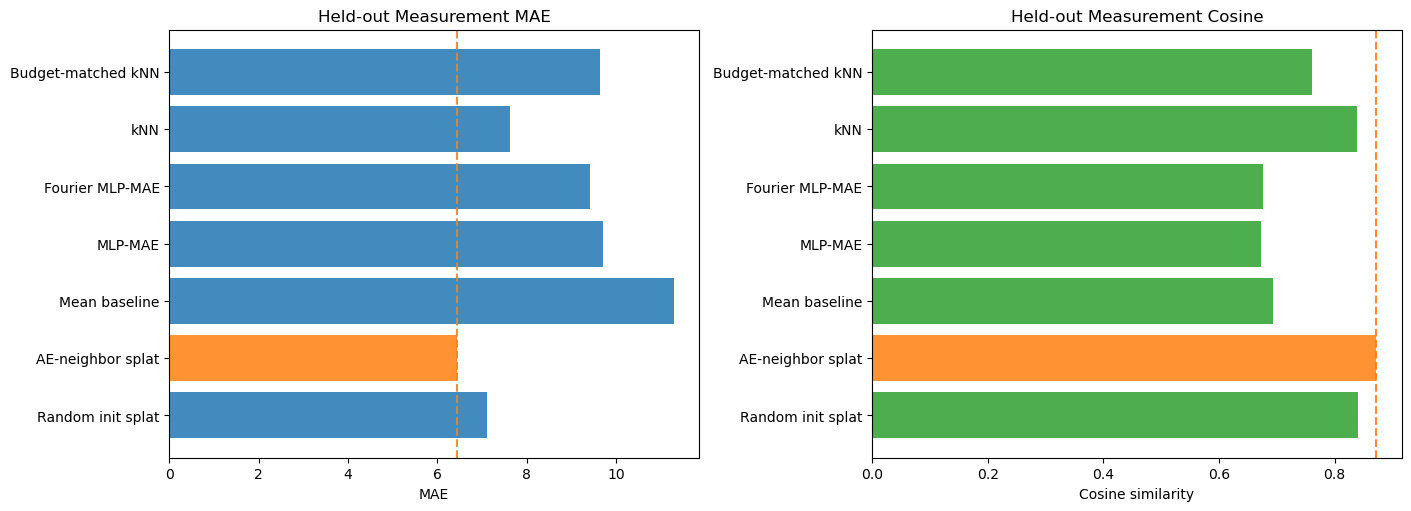

In [11]:
comparison_summary = {
    "Random init splat": {
        "val": random_coarse_result["val_metrics"],
        "heldout": random_coarse_result["test_metrics"],
    },
    "AE-neighbor splat": {
        "val": ae_coarse_result["val_metrics"],
        "heldout": ae_coarse_result["test_metrics"],
    },
    "Mean baseline": {"val": mean_val, "heldout": mean_test},
    "MLP-MAE": {"val": mlp_val, "heldout": mlp_test},
    "Fourier MLP-MAE": {"val": fourier_val, "heldout": fourier_test},
    "kNN": {"val": knn_val, "heldout": knn_test},
    "Budget-matched kNN": {"val": budget_knn_val, "heldout": budget_knn_test},
}
print("Holdout comparison summary")
print(format_for_display(comparison_summary))

method_names = list(comparison_summary.keys())
heldout_mae = [comparison_summary[name]["heldout"]["mae"] for name in method_names]
heldout_cos = [comparison_summary[name]["heldout"]["cosine"] for name in method_names]

ae_idx = method_names.index("AE-neighbor splat")
ae_mae = heldout_mae[ae_idx]
ae_cos = heldout_cos[ae_idx]
bar_colors_mae = ["tab:orange" if name == "AE-neighbor splat" else "tab:blue" for name in method_names]
bar_colors_cos = ["tab:orange" if name == "AE-neighbor splat" else "tab:green" for name in method_names]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
mae_bars = axes[0].barh(method_names, heldout_mae, color=bar_colors_mae, alpha=0.85)
axes[0].axvline(ae_mae, color="tab:orange", linestyle="--", linewidth=1.5, alpha=0.9)
axes[0].set_title("Held-out Measurement MAE")
axes[0].set_xlabel("MAE")

cos_bars = axes[1].barh(method_names, heldout_cos, color=bar_colors_cos, alpha=0.85)
axes[1].axvline(ae_cos, color="tab:orange", linestyle="--", linewidth=1.5, alpha=0.9)
axes[1].set_title("Held-out Measurement Cosine")
axes[1].set_xlabel("Cosine similarity")

export_figure_axes(fig, fallback_prefix="holdout_bars")
plt.show()


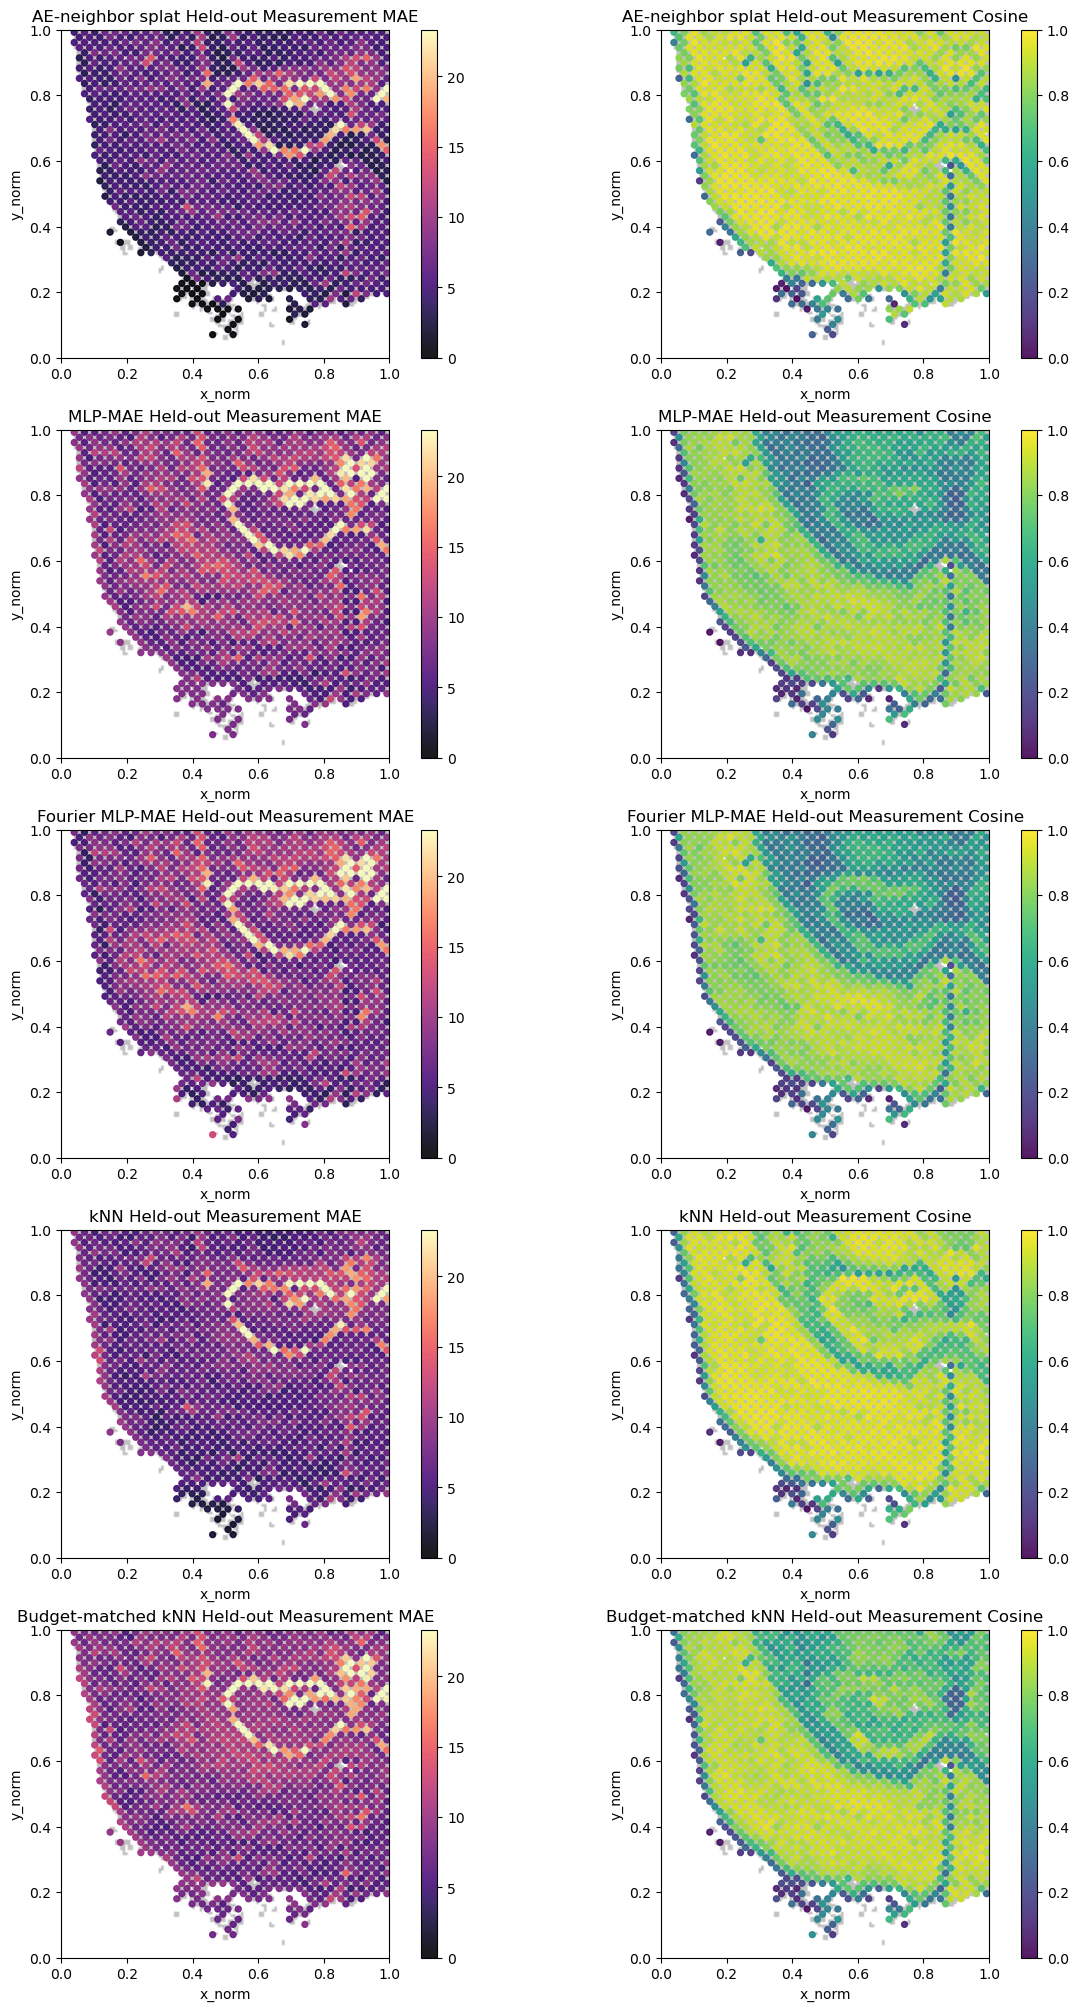

In [12]:
def predict_counts_cell_model(model, features, spans, batch_size=512):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(predict_cell_log_rates(model, features[start:start + batch_size], spans[start:start + batch_size], batch_size=batch_size)))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)

def predict_counts_direct_model(model, features, batch_size=512):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(model(features[start:start + batch_size])))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)

def cosine_per_measurement(pred_counts, true_counts):
    pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    true_norm = true_counts / true_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    return (pred_norm * true_norm).sum(dim=1).detach().cpu().numpy()

heldout_features = measurement_features[measurement_test_idx]
heldout_spans = measurement_spans[measurement_test_idx]
heldout_targets = measurement_targets[measurement_test_idx]
heldout_points_np = heldout_features.detach().cpu().numpy()

comparison_models = [
    ("AE-neighbor splat", ae_coarse_result["model"], "cell_model"),
    ("MLP-MAE", mlp_model, "direct_model"),
    ("Fourier MLP-MAE", fourier_model, "direct_model"),
    ("kNN", knn_model, "direct_model"),
    ("Budget-matched kNN", budget_knn, "direct_model"),
]

plot_specs = []
for label, model, model_kind in comparison_models:
    if model_kind == "cell_model":
        pred_counts = predict_counts_cell_model(model, heldout_features, heldout_spans)
    else:
        pred_counts = predict_counts_direct_model(model, heldout_features)
    mae_values = (pred_counts - heldout_targets).abs().mean(dim=1).detach().cpu().numpy()
    cosine_values = cosine_per_measurement(pred_counts, heldout_targets)
    plot_specs.append((label, mae_values, cosine_values))

mae_vmax = np.quantile(np.concatenate([mae for _, mae, _ in plot_specs]), 0.98)

fig, axes = plt.subplots(len(plot_specs), 2, figsize=(12, 4 * len(plot_specs)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, mae_values, cosine_values) in enumerate(plot_specs):
    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
    sc0 = ax0.scatter(heldout_points_np[:, 0], heldout_points_np[:, 1], c=mae_values, s=18, cmap="magma", alpha=0.9, vmin=0.0, vmax=mae_vmax)
    ax0.set_title(f"{label} Held-out Measurement MAE")
    ax0.set_xlim(0, 1)
    ax0.set_ylim(0, 1)
    ax0.set_aspect("equal")
    ax0.set_xlabel("x_norm")
    ax0.set_ylabel("y_norm")
    fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)

    ax1 = axes[row, 1]
    ax1.imshow(mask_np.astype(float), origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
    sc1 = ax1.scatter(heldout_points_np[:, 0], heldout_points_np[:, 1], c=cosine_values, s=18, cmap="viridis", alpha=0.9, vmin=0.0, vmax=1.0)
    ax1.set_title(f"{label} Held-out Measurement Cosine")
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    ax1.set_aspect("equal")
    ax1.set_xlabel("x_norm")
    ax1.set_ylabel("y_norm")
    fig.colorbar(sc1, ax=ax1, fraction=0.046, pad=0.04)

export_figure_axes(fig, fallback_prefix="heldout_maps")
plt.show()

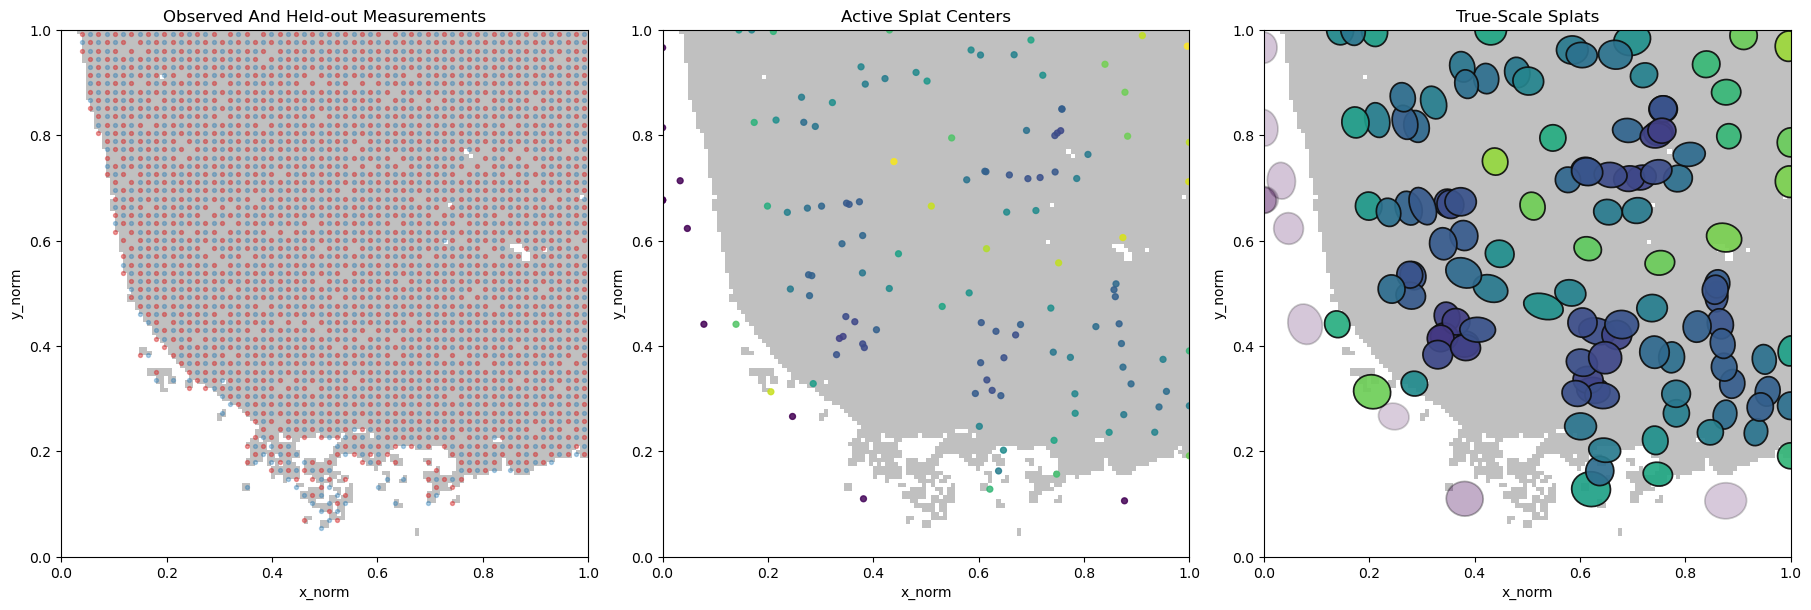

In [13]:
true_scale_model = ae_coarse_result["model"]
with torch.no_grad():
    layout_weights = compute_splat_weights(true_scale_model, measurement_features)
    layout_mean_usage = layout_weights.mean(dim=0).detach().cpu().numpy()
    layout_full_weights = layout_weights.detach().cpu().numpy()
    layout_means = true_scale_model.means.detach().cpu().numpy()
    layout_scales_xy = torch.exp(true_scale_model.log_scales).detach().cpu().numpy()
    layout_rotation = true_scale_model.rotation.detach().cpu().numpy().reshape(-1)

active_idx = np.flatnonzero(layout_mean_usage > 1e-4)
overlap_usage = np.zeros(len(layout_mean_usage), dtype=np.float64)
for splat_idx in active_idx:
    dx = measurement_points_np[:, 0] - layout_means[splat_idx, 0]
    dy = measurement_points_np[:, 1] - layout_means[splat_idx, 1]
    theta = -float(layout_rotation[splat_idx])
    c, s = np.cos(theta), np.sin(theta)
    x_rot = c * dx - s * dy
    y_rot = s * dx + c * dy
    sx = max(float(layout_scales_xy[splat_idx, 0]), 1e-8)
    sy = max(float(layout_scales_xy[splat_idx, 1]), 1e-8)
    inside_mask = (x_rot / sx) ** 2 + (y_rot / sy) ** 2 <= 1.0
    if inside_mask.any():
        overlap_usage[splat_idx] = float(layout_full_weights[inside_mask, splat_idx].mean())
    else:
        overlap_usage[splat_idx] = float(layout_mean_usage[splat_idx])

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

axes[0].imshow(mask_np.astype(float), origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
axes[0].scatter(measurement_points_np[train_mask_np, 0], measurement_points_np[train_mask_np, 1], s=8, alpha=0.35, color="tab:blue")
axes[0].scatter(measurement_points_np[test_mask_np, 0], measurement_points_np[test_mask_np, 1], s=8, alpha=0.45, color="tab:red")
axes[0].set_title("Observed And Held-out Measurements")

axes[1].imshow(mask_np.astype(float), origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
axes[1].scatter(layout_means[active_idx, 0], layout_means[active_idx, 1], s=18, alpha=0.85, c=overlap_usage[active_idx], cmap="viridis")
axes[1].set_title("Active Splat Centers")

axes[2].imshow(mask_np.astype(float), origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.25)
for splat_idx in active_idx:
    alpha = float(np.clip(0.18 + 8.0 * overlap_usage[splat_idx], 0.18, 0.92))
    edge_alpha = float(np.clip(0.45 + 10.0 * overlap_usage[splat_idx], 0.45, 1.0))
    ellipse = Ellipse(
        xy=layout_means[splat_idx],
        width=2.0 * layout_scales_xy[splat_idx, 0],
        height=2.0 * layout_scales_xy[splat_idx, 1],
        angle=np.degrees(layout_rotation[splat_idx]),
        facecolor=plt.cm.viridis(np.clip(overlap_usage[splat_idx], 0.0, 1.0)),
        edgecolor=(0.05, 0.05, 0.05, edge_alpha),
        linewidth=1.25,
        alpha=alpha,
    )
    axes[2].add_patch(ellipse)
axes[2].set_title("True-Scale Splats")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix="true_scale_splats")
plt.show()